# **CHAPTER 2 Vectors, Matrices and Multidimensional Arrays**

The multidimensional data array provided by NumPy is a foundation for nearly all numerical libraries for Python. Spending time on getting familiar with NumPy and developing an understanding of how NumPy works is therefore important.

---

## 2.1 Importing the modules

In order to use the NumPy library, we need to import it in our program (i.e, importing the whole module and use dot notation, thus, avoiding naming conflicts). By convention, the NumPy module is imported under the alias np (using aliases for module names), like so:

<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
    <strong>Note:</strong> The NumPy library provides data structures for representing a rich variety of arrays and methods and functions for operating on such arrays. NumPy provides the numerical backend for nearly every scientific or technical library for Python. It is therefore a very important part of the scientific Python ecosystem. 
</div>

In [ ]:
import numpy as np

After this, we can access functions and classes in the `numpy` module using the `np` namespace. Throughout this book, we assume that the NumPy module is imported in this way.

---

## 2.2 The NumPy array object

<p>
  The core of the NumPy library is the data structure for
  representing multidimensional arrays of homogeneous data.
  Homogeneous refers to all elements in an array having the
  same data type.<sup><a href="#footnote-1" id="ref-1">1</a></sup> The 
  main data structure for multidimensional arrays in NumPy is the 
  <code>ndarray</code> class. In addition to the data stored in the 
  array, this data structure also contains important metadata about the 
  array, such as its shape, size, data type, and other attributes. See
  Table 2-1 for a more detailed description of these attributes. A full 
  list of attributes with descriptions is available in the 
  <code>ndarray</code> docstring, which can be accessed by calling 
  <code>help(np.ndarray)</code> in the Python interpreter or 
  <code>np.ndarray?</code> in an IPython console.
 
</p>

<!-- footnote separator -->
<hr style="width: 100%; margin-left: 0;">

<!-- footnote -->
<p id="footnote-1" style="font-size: 0.9em;">
  <sup>1</sup> This does not necessarily need to be the case
  for Python lists, which therefore can be heterogeneous.
</p>

The main data structure for multidimensional arrays in NumPy is the `ndarray` class. In the following example, an ndarray instance `data` is created **from a nested Python list** using the function `np.array`.

In [ ]:
data = np.array([[1, 2, 3], [4, 5, 6]])
print(type(data))

<class 'numpy.ndarray'>


In [ ]:
data

array([[1, 2, 3],
       [4, 5, 6]])

In [ ]:
print(data)

[[1 2 3]
 [4 5 6]]


In addition to the data stored in the array, this data structure (`ndarray` class) also contains important metadata about the array, such as its shape, size, data type, and other attributes. The following table summarizes some of the basic attributes of the `ndarray` class:

<div align="center">
    <p>
        <strong>Table 2-1. Basic Attributes of the <code>ndarray</code> Class</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>Attribute</th>
            <th>Description</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>shape</code></td>
            <td>A tuple that contains the number of elements (i.e., the length) for each dimension (axis) of the array.</td>
        </tr>
        <tr>
            <td><code>size</code></td>
            <td>The total number of elements in the array.</td>
        </tr>
        <tr>
            <td><code>ndim</code></td>
            <td>Number of dimensions (axes).</td>
        </tr>
        <tr>
            <td><code>nbytes</code></td>
            <td>Number of bytes used to store the data.</td>
        </tr>
        <tr>
            <td><code>dtype</code></td>
            <td>The data type of the elements in the array.</td>
        </tr>
    </tbody>
</table>

<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
    <strong>Note:</strong> The <code>size</code> attribute represents the total number of elements in the array, for example, if a array has a shape of (3, 2, 3, 3), the <code>size</code> attribute would be 54. It is just the application of the multiplication rule of counting, which states that if there are n ways to do one thing and m ways to do another, then there are n * m ways of doing both. In this case, the total number of elements is 3 * 2 * 3 * 3 = 54. This a foundational fundamental topic in Combinatorics, which is the branch of mathematics that studies the counting, arrangement, and combination of objects.
</div>


The following examples demonstrates how these attributes are accessed for an instance `data` of the class `ndarray`:

**Attribute `shape`: A tuple that contains the number of elements (i.e., the length) for each dimension (axis) of the array.**

In [ ]:
data.shape

(2, 3)

**Attribute `size`: The total number of elements in the array**

In [ ]:
data.size

6

**Attribute `ndim`: Number of dimensions (axes)**

In [ ]:
data.ndim

2

**Attribute `nbytes`: Number of bytes used to store the data**

In [ ]:
data.nbytes

48

**Attribute `dtype`: The data type of the elements in the array**

In [ ]:
data.dtype

dtype('int64')

Remember, since NumPy arrays are homogeneous, all elements have the same data type.

### 2.2.1 Why do we use `np.array(...)` to create an `ndarray`?

Although `ndarray` is the class of NumPy arrays, the usual way to create an instance is with the function `np.array(...)`. This is because `np.array(...)` is a **high-level factory function**: it takes ordinary Python data such as lists or tuples, inspects that data, determines a suitable shape and data type, allocates the required memory, and then returns an instance of `ndarray`.

By contrast, `np.ndarray(...)` is a **low-level constructor**. It is designed for advanced use cases where you want to specify details such as the shape, data type, memory buffer, offset, or strides manually. It does **not** behave like `np.array(...)`, and it is not meant to be called with nested Python lists such as `np.ndarray([[1, 2], [3, 4]])`.

In fact, the constructor is conceptually closer to this form:

```python
np.ndarray(shape, dtype=float, buffer=None, offset=0, strides=None, order=None)
```

So, if you want to build an array from Python values, use:

```python
data = np.array([[1, 2, 3], [4, 5, 6]])
```

If you call `np.ndarray(...)` directly without providing a proper buffer, NumPy may create an array with **uninitialized memory**, which is usually not what you want for beginner-level array creation. In short: `np.array(...)` is the safe and convenient way to create arrays from Python data, while `np.ndarray(...)` is a **lower-level tool for specialized memory-oriented use cases**.

### 2.2.2 Data types 

The basic numerical data types supported in NumPy are shown in the table below. Non-numerical data types, such as strings, objects, and user-defined compound types, are also supported.

<div align="center">
    <p>
        <strong>Table 2-2. Basic Numerical Data Types Available in NumPy</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>dtype</th>
            <th>Variants</th>
            <th>Description</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>int</code></td>
            <td><code>int8</code>, <code>int16</code>, <code>int32</code>, <code>int64</code></td>
            <td>Integers</td>
        </tr>
        <tr>
            <td><code>uint</code></td>
            <td><code>uint8</code>, <code>uint16</code>, <code>uint32</code>, <code>uint64</code></td>
            <td>Unsigned (nonnegative) integers</td>
        </tr>
        <tr>
            <td><code>bool</code></td>
            <td><code>Bool</code></td>
            <td>Boolean (<code>True</code> or <code>False</code>)</td>
        </tr>
        <tr>
            <td><code>float</code></td>
            <td><code>float16</code>, <code>float32</code>, <code>float64</code>, <code>float128</code></td>
            <td>Floating-point numbers</td>
        </tr>
        <tr>
            <td><code>complex</code></td>
            <td><code>complex64</code>, <code>complex128</code>, <code>complex256</code></td>
            <td>Complex-valued floating-point numbers</td>
        </tr>
    </tbody>
</table>

For numerical work the most important data types are int (for integers), float (for floating-point numbers), and complex (for complex floating-point numbers). Each of these data types comes in different sizes, such as int32 for 32-bit integers, int64 for 64-bit integers, etc. This offers more fine-grained control over data types than the ­standard Python types, which only provides one type for integers and one type for floats.

It is usually not necessary to explicitly choose the bit size of the data type to work with, but it is often necessary to explicitly choose whether to use arrays of integers, floating-point numbers, or complex values. The following example demonstrates how to use the `dtype` attribute to generate arrays of integer, float and complex-valued elements:

In [ ]:
a = np.array([1, 2, 3], dtype=np.int32)
b = np.array([1, 2, 3], dtype=np.float64)
c = np.array([1, 2, 3], dtype=np.complex128)

print(f"{a.dtype = }, {b.dtype = }, {c.dtype = }")


a.dtype = dtype('int32'), b.dtype = dtype('float64'), c.dtype = dtype('complex128')


Once a NumPy array is created, its dtype cannot be changed, other than by creating a new copy with type-casted array values. Typecasting an array is straightforward and can be done using either the `np.array` function:

In [ ]:
data_1 = np.array([1, 2, 3], dtype=np.float64)
print(f" {data_1} — {type(data_1)} — {data_1.dtype = }") 
data_2 = np.array(data_1, dtype=np.int32)
print(f" {data_2} — {type(data_2)} — {data_2.dtype = }")

print("───────────────────")

print(data_1)
print(data_2)
print(data_1.dtype == data_2.dtype)

 [1. 2. 3.] — <class 'numpy.ndarray'> — data_1.dtype = dtype('float64')
 [1 2 3] — <class 'numpy.ndarray'> — data_2.dtype = dtype('int32')
───────────────────
[1. 2. 3.]
[1 2 3]
False


or by using the `astype` method of the `ndarray` class:

In [ ]:
data_3 = np.array([1, 2, 3], dtype=np.float64)
data_4 = data_3.astype(np.int32)
print(f"{data_4} — {type(data_4)} — {data_4.dtype=}")

print("───────────────────")

print(data_3)
print(data_4)
print(data_3.dtype == data_4.dtype)

[1 2 3] — <class 'numpy.ndarray'> — data_4.dtype=dtype('int32')
───────────────────
[1. 2. 3.]
[1 2 3]
False


When computing with NumPy arrays, the data type might get promoted from one type to another, if required by the operation. For example, adding float-valued and complex-valued arrays, the resulting array is a complex-valued array:

In [ ]:
d1 = np.array([1, 2, 3], dtype=np.float64)
d2 = np.array([1, 2, 3], dtype=np.complex128)
d3 = d1 + d2
print(f"{d3} — {type(d3)} — {d3.dtype=}")

[2.+0.j 4.+0.j 6.+0.j] — <class 'numpy.ndarray'> — d3.dtype=dtype('complex128')


In some cases, depending on the application and its requirements, it is essential to create arrays with data type appropriately set to, for example, `int` or `complex`. The default type is `float`. Consider the following example:

In [ ]:
d4 = np.sqrt(np.array([1, 2, 3], dtype=np.float64))
print(f"{d4} — {type(d4)} — {d4.dtype=}")

[1.         1.41421356 1.73205081] — <class 'numpy.ndarray'> — d4.dtype=dtype('float64')


In [ ]:
d5 = np.sqrt(np.array([-1, -2, -3], dtype=np.complex128))
print(f"{d5} — {type(d5)} — {d5.dtype=}")

[0.+1.j         0.+1.41421356j 0.+1.73205081j] — <class 'numpy.ndarray'> — d5.dtype=dtype('complex128')


#### 2.2.2.1 Real and imaginary parts 

Regardless of the value of the `dtype` attribute, all NumPy array instances have the attributes `real` and `imag`
 for extracting the real and imaginary parts of the array, respectively:

In [ ]:
d6 = np.array([1, 2, 3], dtype=np.complex128)
print(f"{d6.real} — {type(d6.real)} — {d6.real.dtype = }")
print(f"{d6.imag} — {type(d6.imag)} — {d6.imag.dtype = }")

[1. 2. 3.] — <class 'numpy.ndarray'> — d6.real.dtype = dtype('float64')
[0. 0. 0.] — <class 'numpy.ndarray'> — d6.imag.dtype = dtype('float64')


The same functionality is also provided by the functions `np.real` and `np.imag`, which also can be applied to other array-like objects, such as Python lists. Note that Python itself has support of complex numbers, and the `imag` and `real` attributes are also available for Python scalars.

---

## 📑 2.3 Creating arrays

In this section we focus on functions from the NumPy library that can be used to create `ndarray` instances. Arrays can be generated in a number of ways, depending on their properties and the applications they are used for. For example, as we saw in the previous section, one way to initialize an `ndarray` instance is to use the `np.array` function on a Python list, which, for example, can be explicitly defined. However, this method is obviously limited to small arrays. In many situations it is necessary to generate arrays with elements that follow some given rule, such as filled with constant values, increasing integers, uniformly spaced numbers, random numbers, etc. In other cases we might need to create arrays from data stored in a file. The requirements are many and varied, and the NumPy library provides a comprehensive set of functions for generating arrays of various types. In this section we look in more detail at many of these functions. A summary of frequently used array-generating functions is given in the table below:

<div align="center">
    <p style="text-align: center;">
        <strong>Table 2-3. Summary of NumPy Functions for Generating Arrays</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>Function Name</th>
            <th>Type of Array</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>np.array</code></td>
            <td>Creates an array for which the main parameter is given by an array-like object, which, for example, can be a (nested) Python list, a tuple, an iterable sequence, or another <code>ndarray</code> instance.</td>
        </tr>
        <tr>
            <td><code>np.zeros</code></td>
            <td>Creates an array with the specified dimensions and data type that is filled with zeros.</td>
        </tr>
        <tr>
            <td><code>np.ones</code></td>
            <td>Creates an array with the specified dimensions and data type that is filled with ones.</td>
        </tr>
        <tr>
            <td><code>np.diag</code></td>
            <td>Creates a diagonal array with specified values along the diagonal and zeros elsewhere.</td>
        </tr>
        <tr>
            <td><code>np.arange</code></td>
            <td>Creates an array with evenly spaced values between the specified start, end, and increment values.</td>
        </tr>
        <tr>
            <td><code>np.linspace</code></td>
            <td>Creates an array with evenly spaced values between specified start and end values, using a specified number of elements.</td>
        </tr>
        <tr>
            <td><code>np.logspace</code></td>
            <td>Creates an array with values that are logarithmically spaced between the given start and end values.</td>
        </tr>
        <tr>
            <td><code>np.meshgrid</code></td>
            <td>Generates coordinate matrices (and higher-dimensional coordinate arrays) from one-dimensional coordinate vectors.</td>
        </tr>
        <tr>
            <td><code>np.fromfunction</code></td>
            <td>Creates an array and fills it with values specified by a given function, which is evaluated for each combination of indices for the given array size.</td>
        </tr>
        <tr>
            <td><code>np.fromfile</code></td>
            <td>Creates an array with the data from a binary (or text) file. NumPy also provides a corresponding function <code>np.tofile</code> with which NumPy arrays can be stored to disk and later read back using <code>np.fromfile</code>.</td>
        </tr>
        <tr>
            <td><code>np.genfromtxt</code>, <code>np.loadtxt</code></td>
            <td>Create an array from data read from a text file, for example, a comma-separated value (CSV) file. The function <code>np.genfromtxt</code> also supports data files with missing values.</td>
        </tr>
        <tr>
            <td><code>np.random.rand</code></td>
            <td>Generates an array with random numbers that are uniformly distributed between 0 and 1. Other types of distributions are also available in the <code>np.random</code> module.</td>
        </tr>
    </tbody>
</table>

### 2.3.1 Arrays created from lists and other array-like objects  

Using the np.array function, NumPy arrays can be constructed from explicit Python lists, iterable expressions, and other array-like objects (such as other ndarray instances). For example, to create a one-dimensional array from a Python list, we simply pass the Python list as an argument to the np.array function:

In [ ]:
d7 = np.array([1, 2, 3], dtype=np.float64)
print(f"data: {d7}\ndtype: {d7.dtype}\nndim: {d7.ndim}\nshape: {d7.shape}\nsize: {d7.size}\nnbytes: {d7.nbytes}")

data: [1. 2. 3.]
dtype: float64
ndim: 1
shape: (3,)
size: 3
nbytes: 24


To create a two-dimensional array with the same data as in the previous example, we can use a nested Python list:

In [ ]:
d8 = np.array([[1, 2, 3], [4, 5, 6]], dtype=np.float64)
print(f"data: {d8}\ndtype: {d8.dtype}\nndim: {d8.ndim}\nshape: {d8.shape}\nsize: {d8.size}\nnbytes: {d8.nbytes}")

data: [[1. 2. 3.]
 [4. 5. 6.]]
dtype: float64
ndim: 2
shape: (2, 3)
size: 6
nbytes: 48


### 2.3.2 Arrays filled with constant values

The functions np.zeros and np.ones create and return arrays filled with zeros and ones, respectively. They take, as first argument, an integer or a tuple that describes the number of elements along each dimension of the array. For example, to create a 2 × 3 array filled with zeros, and an array of length 4 filled with ones, we can use:

In [ ]:
d9 = np.zeros((2, 3), dtype=np.float64)
print(f"data: {d9}\ndtype: {d9.dtype}\nndim: {d9.ndim}\nshape: {d9.shape}\nsize: {d9.size}\nnbytes: {d9.nbytes}")
print("───────────────────")
d10 = np.ones((4, 5, 6, 3), dtype=np.float64)
print(f"data: {d10}\ndtype: {d10.dtype}\nndim: {d10.ndim}\nshape: {d10.shape}\nsize: {d10.size}\nnbytes: {d10.nbytes}")

data: [[0. 0. 0.]
 [0. 0. 0.]]
dtype: float64
ndim: 2
shape: (2, 3)
size: 6
nbytes: 48
───────────────────
data: [[[[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]]


 [[[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]

  [[1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]
   [1. 1. 1.]]]


 [[[1. 1. 1.]
   [1. 1.

An array filled with an arbitrary constant value can be generated by first creating an array filled with ones and then multiplying the array with the desired fill value. However, NumPy also provides the function `np.full` that does exactly this in one step. The following two ways of constructing arrays with ten elements, which are initialized to the numerical value 5.4 in this example, produces the same results, but using np.full is slightly more efficient since it avoids the multiplication.

In [ ]:
x1 = 5.31 * np.ones(10)
x2 = np.full(10, 5.31)
print(f"{x1}")
print(f"{x1}")

[5.31 5.31 5.31 5.31 5.31 5.31 5.31 5.31 5.31 5.31]
[5.31 5.31 5.31 5.31 5.31 5.31 5.31 5.31 5.31 5.31]


An already created array can also be filled with constant values using the `np.fill` function, which takes an array and a value as arguments, and set all elements in the array to the given value. The following two methods to create an array therefore give the same 
results:

In [ ]:
x3 = np.empty(5)
x3.fill(4.5)
print(f"{x3}")

x4 = np.full(5, 4.5)
print(f"{x4}")

x5 = np.empty(5, dtype=np.float64)
print(f"{x5}")

[4.5 4.5 4.5 4.5 4.5]
[4.5 4.5 4.5 4.5 4.5]
[4.5 4.5 4.5 4.5 4.5]


In this last example, we also used the `np.empty` function, which generates an array with uninitialized values, of the given size. This function should only be used when the initialization of all elements can be guaranteed by other means, such as an explicit loop over the array elements or another explicit assignment. This function is described in more detail later in this chapter. It is better to use `np.zeros`, `np.ones`, or `np.full` to create arrays with initialized values.

### 2.3.3 Arrays filled with incremental sequences

In numerical computing it is very common to require arrays with evenly spaced values between a starting value and ending value. NumPy provides two similar functions to create such arrays: np.arange and np.linspace. Both functions take three arguments, where the first two arguments are the start and end values. The third argument of np.arange is the increment, while for np.linspace it is the total number of points in the array. For example, to generate arrays with values between 1 and 10, with increment 1, we could use either of the following:

In [ ]:
d11 = np.arange(0.0, 10.0, 1.0)
print(f"{d11} — {type(d11)} — {d11.dtype=}")
d12 = np.linspace(0, 10, 10)
print(f"{d12} — {type(d12)} — {d12.dtype=}")

[0. 1. 2. 3. 4. 5. 6. 7. 8. 9.] — <class 'numpy.ndarray'> — d11.dtype=dtype('float64')
[ 0.          1.11111111  2.22222222  3.33333333  4.44444444  5.55555556
  6.66666667  7.77777778  8.88888889 10.        ] — <class 'numpy.ndarray'> — d12.dtype=dtype('float64')


However, note that np.arange does not include the end value (10), while by default np.linspace does (although this behavior can be changed using the optional `endpoint` keyword argument). Whether to use np.arange or np.linspace is mostly a matter of personal preference, but it is generally recommended to use np.linspace whenever the increment is a noninteger.

<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
    <strong>Note:</strong> It is worth to study the mathematical theory behind the implementation of the <code>np.arange</code> and <code>np.linspace</code> functions, specially the <code>np.linspace</code> function.
</div>

### 2.3.4 Arrays filled with logarithmic sequences

The function np.logspace is similar to np.linspace, but the increments between the elements in the array are logarithmically distributed, and the first two arguments, for the start and end values, are the powers of the optional base keyword argument (which defaults to 10). For example, to generate an array with logarithmically distributed values between 1 and 100, we can use:

In [ ]:
d13 = np.logspace(0, 2, 5)  #  5 data points between 10**0=1 to 10**2=100
print(f"{d13} — {type(d13)} — {d13.dtype=}")

[  1.           3.16227766  10.          31.6227766  100.        ] — <class 'numpy.ndarray'> — d13.dtype=dtype('float64')


<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
    <strong>Note:</strong> Study the mathematical theory of this logarithmic distribution.
</div>

### 2.3.5 Meshgrid arrays

The purpose of `np.meshgrid()` is to take one-dimensional coordinate arrays and expand them into **coordinate matrices**. In plain terms:

In [ ]:
x = np.array([0, 1, 2])
y = np.array([10, 20])

These are only axis values. They describe possible x-values and possible y-values, but not all coordinate pairs. `meshgrid` builds the full 2D coordinate system:

In [ ]:
X, Y = np.meshgrid(x, y)

print(X)
print(Y)

[[0 1 2]
 [0 1 2]]
[[10 10 10]
 [20 20 20]]


Together, X and Y represent the coordinate pairs:

```
(0,10), (1,10), (2,10)
(0,20), (1,20), (2,20)
```

So `meshgrid` does not compute a function by itself. It creates the input coordinate grid where a function can be evaluated. Now, imagine you want to evaluate this function:

```
z = x + y   
```

But you want to evaluate it for many combinations of x and y. Thus, with meshgrid, NumPy creates this:

```
X =
[[0, 1, 2],
 [0, 1, 2]]

Y =
[[10, 10, 10],
 [20, 20, 20]]
```

Now you can do:

In [ ]:
Z = X + Y
print(Z)

[[10 11 12]
 [20 21 22]]


Each element of Z comes from one coordinate pair:

```
Z[0,0] = X[0,0] + Y[0,0] = 0 + 10 = 10
Z[0,1] = X[0,1] + Y[0,1] = 1 + 10 = 11
Z[1,2] = X[1,2] + Y[1,2] = 2 + 20 = 22
```

So the fundamental idea is:

`x-axis values + y-axis values -> full coordinate plane`

**Example 1**

In [ ]:
x1 = np.linspace(-2, 2, 5)
y1 = np.linspace(-1, 1, 3)

print(f"Length of x1: {len(x1)}")
print(f"Length of y1: {len(y1)}")
print()

X1, Y1 = np.meshgrid(x1, y1)

print(X1.shape)
print(Y1.shape)

Length of x1: 5
Length of y1: 3

(3, 5)
(3, 5)


Why (3, 5)? 
Because:

```
len(y) = 3 rows
len(x) = 5 columns
```
For 2D plotting, this is usually what you want.

**Example 2: Evaluating a 2D Function**

`z2= x2**2 + y2**2`

In [ ]:
x2 = np.linspace(-2, 2, 5)
y2 = np.linspace(-2, 2, 5)

print(f"x2: {x2}")
print(f"y2: {y2}")

print("──────────────────────────")

X2, Y2 = np.meshgrid(x2, y2)

Z = X2**2 + Y2**2

print(f"X2: {X2}")
print(f"Y2: {Y2}")

print("──────────────────────────")

print(f"Z: {Z}")

x2: [-2. -1.  0.  1.  2.]
y2: [-2. -1.  0.  1.  2.]
──────────────────────────
X2: [[-2. -1.  0.  1.  2.]
 [-2. -1.  0.  1.  2.]
 [-2. -1.  0.  1.  2.]
 [-2. -1.  0.  1.  2.]
 [-2. -1.  0.  1.  2.]]
Y2: [[-2. -2. -2. -2. -2.]
 [-1. -1. -1. -1. -1.]
 [ 0.  0.  0.  0.  0.]
 [ 1.  1.  1.  1.  1.]
 [ 2.  2.  2.  2.  2.]]
──────────────────────────
Z: [[8. 5. 4. 5. 8.]
 [5. 2. 1. 2. 5.]
 [4. 1. 0. 1. 4.]
 [5. 2. 1. 2. 5.]
 [8. 5. 4. 5. 8.]]


This evaluates the function over a square grid of points. This is useful for surface plots, contour plots, heatmaps, cost functions, potential fields, and robotics maps.

### 2.3.6 Creating uninitialized arrays

To create an array of specific size and data type, but without initializing the elements in the array to any particular values, we can use the function np.empty. The advantage of using this function, for example, instead of np.zeros, which creates an array initialized with zero-valued elements, is that we can avoid the initiation step. If all elements are guaranteed to be initialized later in the code, this can save a little bit of time, especially when working with large arrays. To illustrate the use of the np.empty function, consider the following example:

In [ ]:
np.empty(3, dtype=np.float64)

array([1., 2., 3.])

Here we generated a new array with three elements of type float. There is no guarantee that the elements have any particular values, and the actual values will vary from time to time. For this reason it is important that all values are explicitly assigned before the array is used; otherwise unpredictable errors are likely to arise. Often the np.zeros function is a safer alternative to np.empty, and if the performance gain is not essential, it is better to use np.zeros, to minimize the likelihood of subtle and hard-to-reproduce bugs due to uninitialized values in the array returned by np.empty.

### 2.3.7 Creating arrays with properties of other arrays

It is often necessary to create new arrays that share properties, such as shape and data type, with another array. NumPy provides a family of functions for this purpose: np.ones_like, np.zeros_like, np.full_like, and np.empty_like. A typical use-case is a function that takes arrays of unspecified type and size as arguments and requires working arrays of the same size and type. For example, a boilerplate example of this situation is given in the following function:

In [ ]:
def f(x):
    y = np.ones_like(x)
    return y # compute with x and y

At the first line of the body of this function, a new array y is created using np.ones_like, which results in an array of the same size and data type as x, and filled with ones.

### 2.3.8 Creating matrix arrays

Matrices, or two-dimensional arrays, are an important case for numerical computing. NumPy provides functions for generating commonly used matrices. In particular, the function np.identity generates a square matrix with ones on the diagonal and zeros elsewhere:

In [ ]:
np.identity(4)

array([[1., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 1., 0.],
       [0., 0., 0., 1.]])

The similar function numpy.eye generates matrices with ones on a diagonal (optionally offset). This is illustrated in the following example, which produces matrices with nonzero diagonals above and below the diagonal, respectively:

In [ ]:
print(np.eye(3, k=1))
print("────────────")
print(np.eye(3, k=-1))

[[0. 1. 0.]
 [0. 0. 1.]
 [0. 0. 0.]]
────────────
[[0. 0. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


To construct a matrix with an arbitrary one-dimensional array on the diagonal, we can use the np.diag function (which also takes the optional keyword argument k to specify an offset from the diagonal), as demonstrated here:

In [ ]:
print(np.diag(np.arange(0, 20, 5)))

[[ 0  0  0  0]
 [ 0  5  0  0]
 [ 0  0 10  0]
 [ 0  0  0 15]]


Here we gave a third argument to the np.arange function, which specifies the step size in the enumeration of elements in the array returned by the function. The resulting array therefore contains the values [0, 5, 10, 15], which is inserted on the diagonal of a two-dimensional matrix by the np.diag function.

---

## 2.4 Indexing and slicing

### 2.4.1 One-dimensional arrays

<div align="center">
    <p>
        <strong>Table 2-4. Examples of Array Indexing and Slicing Expressions</strong>
    </p>
</div>


<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>Expression</th>
            <th>Description</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>a[m]</code></td>
            <td>Select element at index <code>m</code>, where <code>m</code> is an integer (start counting from 0).</td>
        </tr>
        <tr>
            <td><code>a[-n]</code></td>
            <td>Select the <code>n</code>th element from the end of the list, where <code>n</code> is an integer. The last element in the list is addressed as <code>-1</code>, the second to last element as <code>-2</code>, and so on.</td>
        </tr>
        <tr>
            <td><code>a[m:n]</code></td>
            <td>Select elements with index starting at <code>m</code> and ending at <code>n - 1</code> (<code>m</code> and <code>n</code> are integers).</td>
        </tr>
        <tr>
            <td><code>a[:]</code> or <code>a[0:-1]</code></td>
            <td>Select all elements in the given axis.</td>
        </tr>
        <tr>
            <td><code>a[:n]</code></td>
            <td>Select elements starting with index 0 and going up to index <code>n - 1</code> (integer).</td>
        </tr>
        <tr>
            <td><code>a[m:]</code> or <code>a[m:-1]</code></td>
            <td>Select elements starting with index <code>m</code> (integer) and going up to the last element in the array.</td>
        </tr>
        <tr>
            <td><code>a[m:n:p]</code></td>
            <td>Select elements with index <code>m</code> through <code>n</code> (exclusive), with increment <code>p</code>.</td>
        </tr>
        <tr>
            <td><code>a[::-1]</code></td>
            <td>Select all the elements, in reverse order.</td>
        </tr>
    </tbody>
</table>

### 2.4.2 Multidimensional arrays

With multidimensional arrays, element selections like those introduced in the previous section can be applied on each axis (dimension). The result is a reduced array where each element matches the given selection rules. As a specific example, consider the following two-dimensional array:

In [ ]:
f = lambda m, n: n + 10 * m
A = np.fromfunction(f, (6, 6), dtype=int)
print(A)

[[ 0  1  2  3  4  5]
 [10 11 12 13 14 15]
 [20 21 22 23 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 52 53 54 55]]


This code creates a 6 by 6 NumPy array.

The function:

`f = lambda m, n: n + 10 * m`

means:

`value = column_index + 10 * row_index`

In `np.fromfunction`, the variables work like this:

```
m = row index
n = column index
```

So NumPy fills the array by evaluating:

`A[m, n] = n + 10 * m`

For example:

```
A[0, 0] = 0 + 10*0 = 0
A[0, 1] = 1 + 10*0 = 1
A[1, 0] = 0 + 10*1 = 10
A[2, 3] = 3 + 10*2 = 23
A[5, 5] = 5 + 10*5 = 55
```

`np.fromfunction()` creates an array by applying a function to every position of the array.

So this:

`A = np.fromfunction(f, (6, 6), dtype=int)`

means:

```
Create an array with shape (6, 6).
For each position (m, n), compute f(m, n).
Store the result in A[m, n].
```

>**Important detail**
>
>Although it looks like f receives one m and one n at a time, NumPy actually passes full index arrays. Internally, it behaves conceptually like this:
>
>```
>m =
>[[0, 0, 0, 0, 0, 0],
> [1, 1, 1, 1, 1, 1],
> [2, 2, 2, 2, 2, 2],
> [3, 3, 3, 3, 3, 3],
> [4, 4, 4, 4, 4, 4],
> [5, 5, 5, 5, 5, 5]]
>```
>
>```
>n =
>[[0, 1, 2, 3, 4, 5],
> [0, 1, 2, 3, 4, 5],
> [0, 1, 2, 3, 4, 5],
> [0, 1, 2, 3, 4, 5],
> [0, 1, 2, 3, 4, 5],
> [0, 1, 2, 3, 4, 5]]
>```
>
>Then it computes:
>
>`A = n + 10 * m`
>
>That gives:
>
>```
>[[ 0,  1,  2,  3,  4,  5],
> [10, 11, 12, 13, 14, 15],
> [20, 21, 22, 23, 24, 25],
> [30, 31, 32, 33, 34, 35],
> [40, 41, 42, 43, 44, 45],
> [50, 51, 52, 53, 54, 55]]
>```

<!-- Now, we can use indexing and slicing to select elements, columns and rows from this two-dimensional array. For example: -->

In [ ]:
thin_dash = "─" * 25
print(A[1, 1])    # the element in the second row and second column
print(thin_dash)
print(A[:, 1])    # the second column
print(thin_dash)
print(A[1, :])    # the second row
print(thin_dash)
print(A[:3, :3])  # upper half diagonal block matrix
print(thin_dash)
print(A[3:, 3:])  # lower half diagonal block matrix

11
─────────────────────────
[ 1 11 21 31 41 51]
─────────────────────────
[10 11 12 13 14 15]
─────────────────────────
[[ 0  1  2]
 [10 11 12]
 [20 21 22]]
─────────────────────────
[[33 34 35]
 [43 44 45]
 [53 54 55]]


With element spacing other that 1, submatrices made up from nonconsecutive elements can be extracted:

In [ ]:
print(A[::2, ::2])    # every second element starting from 0, 0
print(thin_dash)
print(A[1::2, 1::3])  # every second and third element starting from 1, 1

[[ 0  2  4]
 [20 22 24]
 [40 42 44]]
─────────────────────────
[[11 14]
 [31 34]
 [51 54]]


This ability to extract subsets of data from a multidimensional array is a simple but very powerful feature with many data processing applications.

In [ ]:
print(A)
print(A.shape)
print(A.size)
print(A.ndim)
print(thin_dash)
print(A[1, 1])



[[ 0  1  2  3  4  5]
 [10 11 12 13 14 15]
 [20 21 22 23 24 25]
 [30 31 32 33 34 35]
 [40 41 42 43 44 45]
 [50 51 52 53 54 55]]
(6, 6)
36
2
─────────────────────────
11


### 2.4.3 Views

Subarrays that are extracted from arrays using slice operations are alternative views of the same underlying array data. That is, they are arrays that refer to the same data in the memory as the original array, but with a different strides configuration. When elements in a view are assigned new values, the values of the original array are therefore also updated. For example,

In [ ]:
B = A[1:5, 1:5]
print(B[:, :])
B[:, :] = 0
print(thin_dash)
print(A)

[[11 12 13 14]
 [21 22 23 24]
 [31 32 33 34]
 [41 42 43 44]]
─────────────────────────
[[ 0  1  2  3  4  5]
 [10  0  0  0  0 15]
 [20  0  0  0  0 25]
 [30  0  0  0  0 35]
 [40  0  0  0  0 45]
 [50 51 52 53 54 55]]


This fact is related to the main concept of copying a list in Python. When you create a view of an array, it does not create a new copy of the data; instead, it creates a new array object that references the same data in memory. This means that if you modify the view, the original array will also be affected, and vice versa.

>To copy a list, you make a slice that includes the entire original list by omitting the first and second indices: `[:]`. This tells Python to make a slice that starts at the first item and ends with the last item, producing a copy of the entire list.
>
>If you simply set `new_list = old_list`, both variables point to the same list. Changes to one will appear in the other. To get two independent lists, always use the **slice copy**.
>
>```
># WRONG — both point to the same list
>strategy_b_symbols = strategy_a_symbols
>
># CORRECT — independent copy
>strategy_b_symbols = strategy_a_symbols[:]
>```

The fact that extracting subarrays results in views rather than new independent arrays eliminates the need for copying data and improves performance. When a copy rather than a view is needed, the view can be copied explicitly by using the `copy` method of the ndarray instance.

In [ ]:
C = B[1:3, 1:3].copy()
print(C)
print(thin_dash)
C[:, :] = 5
print(f"B: {B}")
print(thin_dash)
print(f"C: {C}")


[[0 0]
 [0 0]]
─────────────────────────
B: [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
─────────────────────────
C: [[5 5]
 [5 5]]


In addition to the `copy()` method of the `ndarray` class, an array can also be copied using the function `np.copy()` or, equivalently, using the `np.array` function with the keyword argument `copy=True`.

### 📑 2.4.4 Fancy indexing and boolean-valued indexing

In the previous section, we looked at indexing NumPy arrays with integers and slices, to extract individual elements or ranges of elements. NumPy provides another convenient method to index arrays, called fancy indexing. With fancy indexing, an array can be indexed with another NumPy array, a Python list, or a sequence of integers, whose values select elements in the indexed array. To clarify this concept, consider the following example: we first create a NumPy array with 11 floating-point numbers, and then index the array with another NumPy array (and Python list), to extract element numbers 0, 2, and 4 from the original array:

In [ ]:
D = np.linspace(0, 1, 11)
E = D[np.array([0, 2, 4])]
print(D)
print(thin_dash)
print(E)
print(thin_dash)
F = D[[0, 2, 4]]
print(F)

[0.  0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]
─────────────────────────
[0.  0.2 0.4]
─────────────────────────
[0.  0.2 0.4]


This method of indexing can be used along each axis (dimension) of a multidimensional NumPy array. It requires that the elements in the array or list used for indexing are integers.

Another variant of indexing NumPy arrays is to use Boolean-valued index arrays. In this case, each element (with values True or False) indicates whether or not to select the element from the list with the corresponding index.

In [ ]:
F = D > 0.5
print(F)
D[D > 0.5]

[False False False False False False  True  True  True  True  True]


array([0.6, 0.7, 0.8, 0.9, 1. ])

Unlike arrays created by using slices, the arrays returned using fancy indexing and Boolean-valued indexing are not views but rather new independent arrays. Nonetheless, it is possible to assign values to elements selected using fancy indexing:

In [ ]:
A1 = np.arange(10)
print(f"A1: {A1}")
print(thin_dash)
indices = [2, 4, 6]
B1 = A1[indices]
print(f"B1: {B1}")
print(thin_dash)
B1[:] = -1  # this does not affect A
print(f"A1: {A1}")
print(thin_dash)
print(f"B1: {B1}")



A1: [0 1 2 3 4 5 6 7 8 9]
─────────────────────────
B1: [2 4 6]
─────────────────────────
A1: [0 1 2 3 4 5 6 7 8 9]
─────────────────────────
B1: [-1 -1 -1]


and likewise for Boolean-valued indexing:

In [ ]:
A2 = np.arange(10)
print(f"A2: {A2}")
print(thin_dash)
B2 = A2[A2 > 5]
print(f"B2: {B2}")
print(thin_dash)
B2[0] = -1  # this does not affect A
print(f"A2: {A2}")
print(thin_dash)
print(f"B2: {B2}")

A2: [0 1 2 3 4 5 6 7 8 9]
─────────────────────────
B2: [6 7 8 9]
─────────────────────────
A2: [0 1 2 3 4 5 6 7 8 9]
─────────────────────────
B2: [-1  7  8  9]


---

## 2.5 Reshaping and resizing

When working with data in array form, it is often useful to rearrange arrays and alter the way they are interpreted. For example, an N × N matrix array could be rearranged into a vector of length N<sup>2</sup>, or a set of one-dimensional arrays could be concatenated together or stacked next to each other to form a matrix. NumPy provides a rich set of functions of this type of manipulation. See the following table for a summary of a selection of these functions.

<div align="center">
    <p>
        <strong>Table 2-5. Summary of NumPy Functions for Manipulating the Dimensions and the Shape of Arrays</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>Function/Method</th>
            <th>Description</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>np.reshape</code>, <code>np.ndarray.reshape</code></td>
            <td>Reshape an N-dimensional array. The total number of elements must remain the same.</td>
        </tr>
        <tr>
            <td><code>np.ndarray.flatten</code></td>
            <td>Creates a copy of an N-dimensional array, and reinterpret it as a one-dimensional array (i.e., all dimensions are collapsed into one).</td>
        </tr>
        <tr>
            <td><code>np.ravel</code>, <code>np.ndarray.ravel</code></td>
            <td>Create a view (if possible, otherwise a copy) of an N-dimensional array in which it is interpreted as a one-dimensional array.</td>
        </tr>
        <tr>
            <td><code>np.squeeze</code></td>
            <td>Removes axes with length 1.</td>
        </tr>
        <tr>
            <td><code>np.expand_dims</code>, <code>np.newaxis</code></td>
            <td>Add a new axis (dimension) of length 1 to an array, where <code>np.newaxis</code> is used with array indexing.</td>
        </tr>
        <tr>
            <td><code>np.transpose</code>, <code>np.ndarray.transpose</code>, <code>np.ndarray.T</code></td>
            <td>Transpose the array. The transpose operation corresponds to reversing (or more generally, permuting) the axes of the array.</td>
        </tr>
        <tr>
            <td><code>np.hstack</code></td>
            <td>Stacks a list of arrays horizontally (along axis 1): for example, given a list of column vectors, appends the columns to form a matrix.</td>
        </tr>
        <tr>
            <td><code>np.vstack</code></td>
            <td>Stacks a list of arrays vertically (along axis 0): for example, given a list of row vectors, appends the rows to form a matrix.</td>
        </tr>
        <tr>
            <td><code>np.dstack</code></td>
            <td>Stacks arrays depth-wise (along axis 2).</td>
        </tr>
        <tr>
            <td><code>np.concatenate</code></td>
            <td>Creates a new array by appending arrays after each other, along a given axis.</td>
        </tr>
        <tr>
            <td><code>np.resize</code></td>
            <td>Resizes an array. Creates a new copy of the original array, with the requested size. If necessary, the original array will be repeated to fill up the new array.</td>
        </tr>
        <tr>
            <td><code>np.append</code></td>
            <td>Appends an element to an array. Creates a new copy of the array.</td>
        </tr>
        <tr>
            <td><code>np.insert</code></td>
            <td>Inserts a new element at a given position. Creates a new copy of the array.</td>
        </tr>
        <tr>
            <td><code>np.delete</code></td>
            <td>Deletes an element at a given position. Creates a new copy of the array.</td>
        </tr>
    </tbody>
</table>

In NumPy, the function np.reshape, or the ndarray class method reshape, can be used to reconfigure how the underlying data is interpreted. It takes an array and the new shape of the array as arguments:

### 2.5.1 Reshaping arrays

In [ ]:
a1 = np.array([[1, 2], [3, 4], [5, 6]])
print(a1)

# using the function np.reshape
a2 = np.reshape(a1, (2, 3))
print(thin_dash)
print(a2)

# using the ndarray class method reshape
a3 = a1.reshape((2, 3))
print(thin_dash)
print(a3)

[[1 2]
 [3 4]
 [5 6]]
─────────────────────────
[[1 2 3]
 [4 5 6]]
─────────────────────────
[[1 2 3]
 [4 5 6]]


**It is necessary that the requested new shape of the array match the number of elements in the original size**. However, the number of axes (dimensions) does not need to be conserved, as illustrated in the previous example, where in the first case, the new array has dimension 2 and shape (1, 4), while in the second case, the new array has dimension 1 and shape (4,). This example also demonstrates two different ways of invoking the reshape operation: using the function np.reshape and the ndarray method reshape. **Note that reshaping an array produces a view of the array, and if an independent copy of the array is needed, the view has to be copied explicitly (e.g., using np.copy)**.

In [ ]:
a4 = np.copy(a3)

a2[0, 1] = 100
print(a1)  # a1 is affected because a2 is a view of a1

a3[0, 0] = 200
print(thin_dash)
print(a1)  # a1 is affected because a3 is a view of a1

print(thin_dash)
print(a4)  # a4 is not affected because it is a copy of a3


[[  1 100]
 [  3   4]
 [  5   6]]
─────────────────────────
[[200 100]
 [  3   4]
 [  5   6]]
─────────────────────────
[[1 2 3]
 [4 5 6]]


The `np.ravel` (and its corresponding `ndarray` method) is a special case of reshape, which collapses all dimensions of an array and returns a flattened one-dimensional array with a length that corresponds to the total number of elements in the original array. The ndarray method `flatten` performs the same function but returns a copy instead of a view.

In [ ]:
a4 = np.array([[1, 2, 3], [4, 5, 6]])
print(thin_dash)
print(a4)  # original array remains unchanged before ravel()
print(thin_dash)
a5 = a4.ravel()  # create a flattened view of a4
a5[5] = 999
print(a5)
print(thin_dash)
print(a4)  # original array is affected because a5 is a view of a4
print(thin_dash)

print()

print(thin_dash)
a6 = a4.flatten()  # create a flattened copy of a4
a6[2] = 999
print(a6)  # flattened copy of a4, original array is not affected
print(thin_dash)
print(a4)  # original array remains unchanged after flatten()
print(thin_dash)

─────────────────────────
[[1 2 3]
 [4 5 6]]
─────────────────────────
[  1   2   3   4   5 999]
─────────────────────────
[[  1   2   3]
 [  4   5 999]]
─────────────────────────

─────────────────────────
[  1   2 999   4   5 999]
─────────────────────────
[[  1   2   3]
 [  4   5 999]]
─────────────────────────


While `np.ravel` and `np.flatten` collapse the axes of an array into a one-dimensional array, it is also possible to introduce new axes into an array, either by using `np.reshape` or, when adding new empty axes, using indexing notation and the `np.newaxis` keyword at the place of a new axis. In the following example, the array `data` has one axis, so it should normally be indexed with a tuple with one element. However, if it is indexed with a tuple with more than one element, and if the extra indices in the tuple have the value `np.newaxis`, then the corresponding new axes are added:

In [ ]:
a7 = np.arange(0, 5)
print(a7)
column_vector = a7[:, np.newaxis]  # convert a7 to a column vector
print(column_vector)  # display the column vector
print(thin_dash)
print(f"a7 size: {a7.size} - a7 shape {a7.shape} - column_vector size: {column_vector.size} - column_vector shape: {column_vector.shape}")

print()

print(f"These operations also generate array views.")
print(thin_dash)
column_vector[0][0]= 999
print(a7)
print(column_vector)

print()

row = a7[np.newaxis, :]  # convert a7 to a row vector
print(row)  # display the row vector
print(thin_dash)
print(f"a7 size: {a7.size} - a7 shape {a7.shape} - row size: {row.size} - row shape: {row.shape}")

[0 1 2 3 4]
[[0]
 [1]
 [2]
 [3]
 [4]]
─────────────────────────
a7 size: 5 - a7 shape (5,) - column_vector size: 5 - column_vector shape: (5, 1)

These operations also generate array views.
─────────────────────────
[999   1   2   3   4]
[[999]
 [  1]
 [  2]
 [  3]
 [  4]]

[[999   1   2   3   4]]
─────────────────────────
a7 size: 5 - a7 shape (5,) - row size: 5 - row shape: (1, 5)


The function `np.expand_dims` can also be used to add new dimensions to an array, and in the preceding example, the expression data[:, np.newaxis] is equivalent to `np.expand_dims(data, axis=1)`, and data[np.newaxis, :] is equivalent to `np.expand_dims(data, axis=0)`. Here the axis argument specifies the location relative to the existing axes where the new axis is to be inserted.

In [ ]:
a8 = np.expand_dims(a7, axis=1)  # convert a7 to a column vector using np.expand_dims
print(a8)  # display the column vector created using np.expand_dims
a9 = np.expand_dims(a7, axis=0)  # convert a7 to a row vector using np.expand_dims
print(a9)  # display the row vector created using np.expand_dims
print(f"a8 and a9 shares memory?: {np.shares_memory(a8, a9)}")

[[999]
 [  1]
 [  2]
 [  3]
 [  4]]
[[999   1   2   3   4]]
a8 and a9 shares memory?: True


### 2.5.2 Resizing arrays

We have up to now looked at methods to rearrange arrays in ways that do not affect the underlying data. Earlier in this chapter, we also looked at how to extract subarrays using various indexing techniques. In addition to reshaping and selecting subarrays, it is often necessary to merge arrays into bigger arrays, for example, when joining separately computed or measured data series into a higher-dimensional array, such as a matrix. For this task, NumPy provides the functions `np.vstack`, for vertical stacking of, for example, rows into a matrix, and `np.hstack` for horizontal stacking of, for example, columns into a matrix. The function `np.concatenate` provides similar functionality, but it takes a keyword argument axis that specifies the axis along which the arrays are to be
­concatenated.

The shape of the arrays passed to np.hstack, np.vstack, and np.concatenate is important to achieve the desired type of array joining. For example, consider the following cases: say we have one-dimensional arrays of data, and we want to stack them vertically to obtain a matrix where the rows are made up of the one-dimensional arrays. We can use np.vstack to achieve thisnp.vstack

<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
    <strong>Note:</strong> <code>np.vstack</code>, <code>np.hstack</code>, and <code>np.concatenate</code> do not generate array views.
</div>

**`np.vstack`**

In [ ]:
a10 = np.arange(5)
print(a10)
print(f"a10 shape {a10.shape} - a10 size {a10.size} - a10 ndim {a10.ndim}")
print(thin_dash)

a11 = np.vstack((a10, a10, a10))  # note the added parentheses to form a tuple
print(a11)  # display the vertically stacked array
print(f"a11 shape {a11.shape} - a11 size {a11.size} - a11 ndim {a11.ndim}")
print(thin_dash)
print(f"a10 and a11 shares memory?: {np.shares_memory(a10, a11)}")

[0 1 2 3 4]
a10 shape (5,) - a10 size 5 - a10 ndim 1
─────────────────────────
[[0 1 2 3 4]
 [0 1 2 3 4]
 [0 1 2 3 4]]
a11 shape (3, 5) - a11 size 15 - a11 ndim 2
─────────────────────────
a10 and a11 shares memory?: False


**`np.hstack`**

In [ ]:
a12 = np.arange(5)
print(a12)
print(f"a12 shape {a12.shape} - a12 size {a12.size} - a12 ndim {a12.ndim}")
print(thin_dash)

a13 = np.hstack((a12, a12, a12))  # note the added parentheses to form a tuple
print(a13)  # display the horizontally stacked array
print(f"a13 shape {a13.shape} - a13 size {a13.size} - a13 ndim {a13.ndim}")
print(thin_dash)
print(f"a12 and a13 shares memory?: {np.shares_memory(a12, a13)}")

[0 1 2 3 4]
a12 shape (5,) - a12 size 5 - a12 ndim 1
─────────────────────────
[0 1 2 3 4 0 1 2 3 4 0 1 2 3 4]
a13 shape (15,) - a13 size 15 - a13 ndim 1
─────────────────────────
a12 and a13 shares memory?: False


This indeed stacks the arrays horizontally, but not in the way intended here. To make `np.hstack` treat the input arrays as columns and stack them accordingly, we need to make the input arrays two-dimensional arrays of shape `(1, 5)` rather than one-­dimensional arrays of shape `(5,)`. As discussed earlier, we can insert a new axis by indexing with `np.newaxis`:

In [ ]:
a12 = a12[:, np.newaxis]  # convert a12 to a 2D column vector
np.hstack((a12, a12, a12))  # horizontally stack the 2D column vector three times

array([[0, 0, 0],
       [1, 1, 1],
       [2, 2, 2],
       [3, 3, 3],
       [4, 4, 4]])

The behavior of the functions for horizontal and vertical stacking, as well as concatenating arrays using `np.concatenate`, is clearest when the stacked arrays have the same number of dimensions as the final array and when the input arrays are stacked along an axis for which they have length 1. 

The number of elements in a NumPy array cannot be changed once the array has been created. To insert, append, and remove elements from a NumPy array, for example, using the function `np.append`, `np.insert`, and `np.delete`, a new array must be created and the data copied to it. It may sometimes be tempting to use these functions to grow or shrink the size of a NumPy array but due to the overhead of creating new arrays and copying the data, it is usually a good idea to preallocate arrays with size such that they do not later need to be resized.

---

## 📑 2.6 Vectorized expressions

The purpose of storing numerical data in arrays is to be able to process the data with concise vectorized expressions that represent batch operations that are applied to all elements in the arrays. Efficient use of vectorized expressions eliminates the need of many explicit for loops. This results in less verbose code, better maintainability, and higher-performing code. NumPy implements functions and vectorized operations corresponding to most fundamental mathematical functions and operators. Many of these functions and operations act on arrays on an elementwise basis, and binary operations require all arrays in an expression to be of compatible size. The meaning of compatible size is normally that the variables in an expression represent either scalars or arrays of the same size and shape. More generally, a binary operation involving two arrays is well defined if the arrays can be broadcasted into the same shape and size.

In the case of an operation between a scalar and an array, broadcasting refers to the scalar being distributed and the operation applied to each element in the array. When an expression contains arrays of unequal sizes, the operations may still be well defined if the smaller of the array can be broadcasted (“effectively expanded”) to match the larger array according to NumPy’s broadcasting rule: an array can be broadcasted over another array if their axes on a one-by-one basis either have the same length or if either of them have length 1. If the number of axes of the two arrays is not equal, the array with fewer axes is padded with new axes of length 1 from the left until the numbers of dimensions of the two arrays agree.

Two simple examples that illustrate array broadcasting are shown in Figure 2-2: a 3 × 3 matrix is added to a 1 × 3 row vector and a 3 × 1 column vector, respectively, and in both cases the result is a 3 × 3 matrix. However, the elements in the two resulting matrices are different, because the way the elements of the row and column vectors are broadcasted to the shape of the larger array is different depending on the shape of the arrays, according to NumPy’s broadcasting rule.

<div align="center">

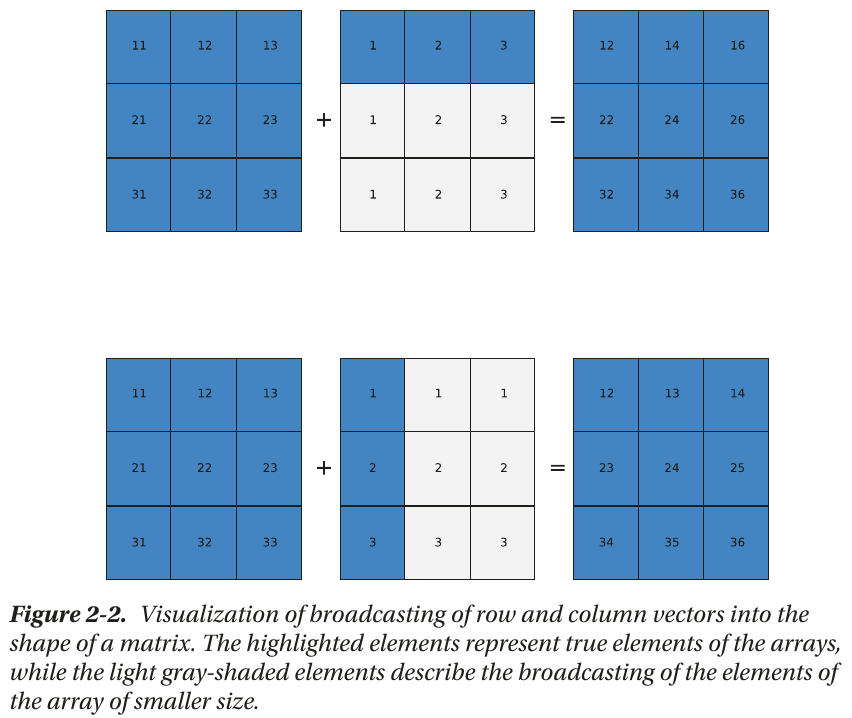

</div>

<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
<strong>Note:</strong> Look at this resource for a better understanding and explanation on Vectorized Expressions in NumPy:

<br>

[First Principles Explanation: Vectorized Expressions in NumPy](https://claude.ai/chat/b8d73803-9bda-4bb2-b863-68622ff2679b)
</div>

### 2.6.1 Arithmetic operations  

The standard arithmetic operations with NumPy arrays perform elementwise operations. Consider, for example, the addition, subtraction,multiplication, and division of equal-sized arrays:

In [ ]:
x1 = np.array([ [1, 2], [3, 4] ])
y1 = np.array([ [5, 6], [7, 8] ])

addition = x1 + y1
print(addition)

print(thin_dash)

subtraction = y1 - x1
print(subtraction)

print(thin_dash)

multiplication = x1 * y1
print(multiplication)

print(thin_dash)

division = y1 / x1
print(division)


[[ 6  8]
 [10 12]]
─────────────────────────
[[4 4]
 [4 4]]
─────────────────────────
[[ 5 12]
 [21 32]]
─────────────────────────
[[5.         3.        ]
 [2.33333333 2.        ]]


In operations between scalars and arrays, the scalar value is applied to each element in the array, as one could expect:

In [ ]:
scalar_multiplication = x1 * 2
print(scalar_multiplication)

print(thin_dash)

exponentiation = 2 ** x1
print(exponentiation)

print(thin_dash)

division_by_scalar = y1 / 2
print(division_by_scalar)

print(thin_dash)

print(division_by_scalar.dtype)

[[2 4]
 [6 8]]
─────────────────────────
[[ 2  4]
 [ 8 16]]
─────────────────────────
[[2.5 3. ]
 [3.5 4. ]]
─────────────────────────
float64


If an arithmetic operation is performed on arrays with incompatible size or shape, a ValueError exception is raised:

In [ ]:
x2 = np.array([ [1, 2, 3], [4, 5, 6] ])
z1 = np.array([ [7, 8], [9, 10], [11, 12] ])

# x2 / z1

A summary of the operators for arithmetic operations with NumPy arrays is given in Table 2-6. These operators use the standard symbols used in Python. The result of an arithmetic operation with one or two arrays is a new independent array, with its own data in the memory. Evaluating complicated arithmetic expression might therefore trigger many memory allocation and copy operations, and when working with large arrays, this can lead to a large memory footprint and impact the performance negatively. In such cases, using inplace operation (see Table 2-6) can reduce the memory footprint and improve performance.

<div align="center">
    <p>
        <strong>Table 2-6. Operators for Elementwise Arithmetic Operation on NumPy Arrays</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>Operator</th>
            <th>Operation</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>+</code>, <code>+=</code></td>
            <td>Addition</td>
        </tr>
        <tr>
            <td><code>-</code>, <code>-=</code></td>
            <td>Subtraction</td>
        </tr>
        <tr>
            <td><code>*</code>, <code>*=</code></td>
            <td>Multiplication</td>
        </tr>
        <tr>
            <td><code>/</code>, <code>/=</code></td>
            <td>Division</td>
        </tr>
        <tr>
            <td><code>//</code>, <code>//=</code></td>
            <td>Integer division</td>
        </tr>
        <tr>
            <td><code>**</code>, <code>**=</code></td>
            <td>Exponentiation</td>
        </tr>
    </tbody>
</table>

As an example of inplace operators, consider the following two statements, which have the same effect:

In [ ]:
# ──────────────────────────────────────────────────────────────────────
# x3 is reassigned to a new array
# ──────────────────────────────────────────────────────────────────────

x3 = np.array([[10, 11, 12], [13, 14, 15]])
y4 = np.array([[16, 17, 18], [19, 20, 21]])
print(x3)
print(thin_dash)

x3 = x3 + y4
print(x3)
print(thin_dash)

# ──────────────────────────────────────────────────────────────────────
# x3     is updated in-place with the addition of y4
# ──────────────────────────────────────────────────────────────────────

x3 = np.array([[10, 11, 12], [13, 14, 15]])
y4 = np.array([[16, 17, 18], [19, 20, 21]])

x3 += y4
print(x3)
print(thin_dash)

[[10 11 12]
 [13 14 15]]
─────────────────────────
[[26 28 30]
 [32 34 36]]
─────────────────────────
[[26 28 30]
 [32 34 36]]
─────────────────────────


The two expressions have the same effect, but in the first case, x is reassigned to a new array, while in the second case, the values of array x are updated inplace. Extensive use of inplace operators tends to impair code readability, and inplace operators should therefore be used only when necessary.

### 2.6.2 Elementwise functions

In addition to arithmetic expressions using operators, NumPy provides vectorized functions for elementwise evaluation of many elementary mathematical functions and operations. Table 2-7 gives a summary of elementary mathematical functions in NumPy.Each of these functions takes a single array (of arbitrary dimension) as input and returns a new array of the same shape, where for each element the function has been applied to the corresponding element in the input array. The data type of the output array is not necessarily the same as that of the input array.

<div align="center">
    <p>
        <strong>Table 2-7. Selection of NumPy Functions for Elementwise Elementary Mathematical Functions</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>NumPy Function</th>
            <th>Description</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>np.cos</code>, <code>np.sin</code>, <code>np.tan</code></td>
            <td>Trigonometric functions.</td>
        </tr>
        <tr>
            <td><code>np.arccos</code>, <code>np.arcsin</code>, <code>np.arctan</code></td>
            <td>Inverse trigonometric functions.</td>
        </tr>
        <tr>
            <td><code>np.cosh</code>, <code>np.sinh</code>, <code>np.tanh</code></td>
            <td>Hyperbolic trigonometric functions.</td>
        </tr>
        <tr>
            <td><code>np.arccosh</code>, <code>np.arcsinh</code>, <code>np.arctanh</code></td>
            <td>Inverse hyperbolic trigonometric functions.</td>
        </tr>
        <tr>
            <td><code>np.sqrt</code></td>
            <td>Square root.</td>
        </tr>
        <tr>
            <td><code>np.exp</code></td>
            <td>Exponential.</td>
        </tr>
        <tr>
            <td><code>np.log</code>, <code>np.log2</code>, <code>np.log10</code></td>
            <td>Logarithms of base e, 2, and 10, respectively.</td>
        </tr>
    </tbody>
</table>

<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
Note that this is not a complete list of the available elementwise functions in NumPy. See the <a href="https://numpy.org/doc/stable/reference/routines.math.html">NumPy reference documentations</a> for comprehensive lists.
</div>

For example, the np.sin function (which takes only one argument) is used to compute the sine function for all values in the array:

In [ ]:
x5 = np.linspace(-1, 1, 11)
print(x5)

print(thin_dash)

y5 = ( np.round(np.sin(np.pi * x5), decimals=4) )
print(y5)

[-1.  -0.8 -0.6 -0.4 -0.2  0.   0.2  0.4  0.6  0.8  1. ]
─────────────────────────
[-0.     -0.5878 -0.9511 -0.9511 -0.5878  0.      0.5878  0.9511  0.9511
  0.5878  0.    ]


Here we also used the constant np.pi and the function np.round to round the values of y to four decimals. Like the np.sin function, many of the elementary math functions take one input array and produce one output array. In contrast, many of the mathematical operator functions (Table 2-8) operates on two input arrays and returns one array:

<div align="center">
    <p>
        <strong>Table 2-8. Summary of NumPy Functions for Elementwise Mathematical Operations</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>NumPy Function</th>
            <th>Description</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>np.add</code>, <code>np.subtract</code>, <code>np.multiply</code>, <code>np.divide</code></td>
            <td>Addition, subtraction, multiplication, and division of two NumPy arrays.</td>
        </tr>
        <tr>
            <td><code>np.power</code></td>
            <td>Raises first input argument to the power of the second input argument (applied elementwise).</td>
        </tr>
        <tr>
            <td><code>np.remainder</code></td>
            <td>The remainder of division.</td>
        </tr>
        <tr>
            <td><code>np.reciprocal</code></td>
            <td>The reciprocal (inverse) of each element.</td>
        </tr>
        <tr>
            <td><code>np.real</code>, <code>np.imag</code>, <code>np.conj</code></td>
            <td>The real part, imaginary part, and the complex conjugate of the elements in the input arrays.</td>
        </tr>
        <tr>
            <td><code>np.sign</code>, <code>np.abs</code></td>
            <td>The sign and the absolute value.</td>
        </tr>
        <tr>
            <td><code>np.floor</code>, <code>np.ceil</code>, <code>np.rint</code></td>
            <td>Convert to integer values.</td>
        </tr>
        <tr>
            <td><code>np.round</code></td>
            <td>Rounds to a given number of decimals.</td>
        </tr>
    </tbody>
</table>

In [ ]:
x6 = np.add(np.sin(x5) ** 2, np.cos(x5) ** 2)
print(x6)

print(thin_dash)

x7 = np.sin(x5) **2 + np.cos(x5) ** 2
print(x7)

[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
─────────────────────────
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


Note that in this example, `np.add` and the operator `+` are equivalent, and for normal use the operator should be used. 

Occasionally it is necessary to define new functions that operate on NumPy arrays on an element-by-element basis. A good way to implement such functions is to express it in terms of already existing NumPy operators and expressions, but in cases when this is not possible, the `np.vectorize` function can be a convenient tool. This function takes a nonvectorized function and returns a vectorized function. For example, consider the following implementation of the Heaviside step function, which works for scalar input:

<div align="center">

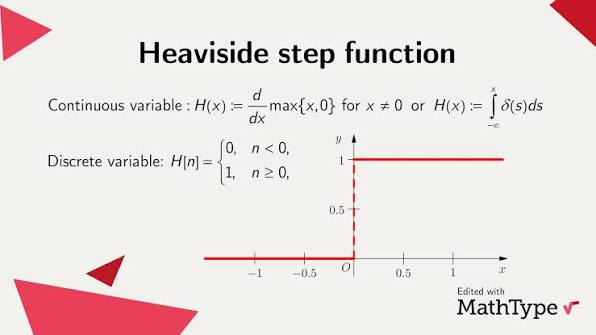

</div>

In [ ]:
def heaviside(x):
    return 1 if x > 0 else 0

In [ ]:
h1 = heaviside(-1)
print(h1)
h2 = heaviside(1.5)
print(h2)

0
1


However, unfortunately this function does not work for NumPy array input:

In [ ]:
h3 = np.linspace(-5, 5, 11)
# heaviside(h3)

Using `np.vectorize` the scalar Heaviside function can be converted into a vectorized function that works with NumPy arrays as input:

In [ ]:
heaviside = np.vectorize(heaviside)
heaviside(h3)

array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1])

Although the function returned by np.vectorize works with arrays, it will be relatively slow since the original function must be called for each element in the array. There are much better ways to implementing this particular function using arithmetic with Boolean-valued arrays, as discussed later in this chapter:

In [ ]:
def heaviside_1(x):
    return 1.0 * (x > 0)

Nonetheless, `np.vectorize` can often be a quick and convenient way to vectorize a function written for scalar input.

### 📑 2.6.3 Aggregate functions

NumPy provides another set of functions for calculating aggregates for NumPy arrays, which take an array as input and by default return a scalar as output. For example, statistics such as averages, standard deviations, and variances of the values in the input array, and functions for calculating the sum and the product of elements in an array, are all aggregate functions.

A summary of aggregate functions is given in Table 2-9. All of these functions are also available as methods in the ndarray class. For example, `np.mean(data)` and `data.mean()` in the following example are equivalent:

In [ ]:
data = np.random.normal(size=(15, 15))
data1 = np.mean(data)
data2 = data.mean()

print(np.round(data1, 6))
print(np.round(data2, 6))

-0.007648
-0.007648


<div align="center">
    <p>
        <strong>Table 2-9. Summary of Aggregate Functions in NumPy</strong>
    </p>
</div>

<table style="margin-left: auto; margin-right: auto;">
    <thead>
        <tr>
            <th>NumPy Function</th>
            <th>Description</th>
        </tr>
    </thead>
    <tbody>
        <tr>
            <td><code>np.mean</code></td>
            <td>The average of the values in the array.</td>
        </tr>
        <tr>
            <td><code>np.std</code></td>
            <td>Standard deviation.</td>
        </tr>
        <tr>
            <td><code>np.var</code></td>
            <td>Variance.</td>
        </tr>
        <tr>
            <td><code>np.sum</code></td>
            <td>Sum of all elements in the array.</td>
        </tr>
        <tr>
            <td><code>np.prod</code></td>
            <td>Product of all elements in the array.</td>
        </tr>
        <tr>
            <td><code>np.cumsum</code></td>
            <td>Cumulative sum of the elements in the array.</td>
        </tr>
        <tr>
            <td><code>np.cumprod</code></td>
            <td>Cumulative product of the elements in the array.</td>
        </tr>
        <tr>
            <td><code>np.min</code>, <code>np.max</code></td>
            <td>The minimum and maximum values in an array.</td>
        </tr>
        <tr>
            <td><code>np.argmin</code>, <code>np.argmax</code></td>
            <td>The indices of the minimum and maximum values in the array.</td>
        </tr>
        <tr>
            <td><code>np.all</code></td>
            <td>Returns True if all elements in the argument array are nonzero.</td>
        </tr>
        <tr>
            <td><code>np.any</code></td>
            <td>Returns True if any of the elements in the argument array is nonzero.</td>
        </tr>
    </tbody>
</table>

By default, the functions in Table 2-9 aggregate over the entire input array. Using the axis keyword argument with these functions, and their corresponding ndarray methods, it is possible to control over which axis in the array aggregation is carried out. The axis argument can be an integer, which specifies the axis to aggregate values over. In many cases the axis argument can also be a tuple of integers, which specifies multiple axes to aggregate over. The following example demonstrates how calling the aggregate function `np.sum` on the array of shape `(5, 10, 15)` reduces the dimensionality of the array depending on the values of the axis argument:

In [ ]:
data3 = np.random.normal(size=(5, 10, 15))
# print(data3)
data3.sum(axis=0).shape

(10, 15)

In [ ]:
data3.sum(axis=(0, 2)).shape

(10,)

In [ ]:
data3.sum()

np.float64(65.50444508066046)

<div style="
    padding: 12px 16px;
    border-left: 5px solid #2f80ed;
    background-color: #eef6ff;
    border-radius: 6px;
    margin: 12px 0;
">
<strong>Note:</strong> Look at this resource for a better understanding and explanation on the <code>ndarray.sum()</code> aggregation function in NumPy:

<br>

[<code>ndarray.sum()</code> explanation](https://chatgpt.com/share/6ae3b002-b974-83e9-8be9-67ff5ac38166)
</div>

A visual illustration of how aggregation over all elements, over the first axis, and over the second axis of a 3 × 3 array is shown in Figure 2-3. In this example, the data array is filled with integers between 1 and 9:

In [ ]:
data4 = np.arange(1, 10).reshape((3, 3))
print(data4)

[[1 2 3]
 [4 5 6]
 [7 8 9]]


<div align="center">

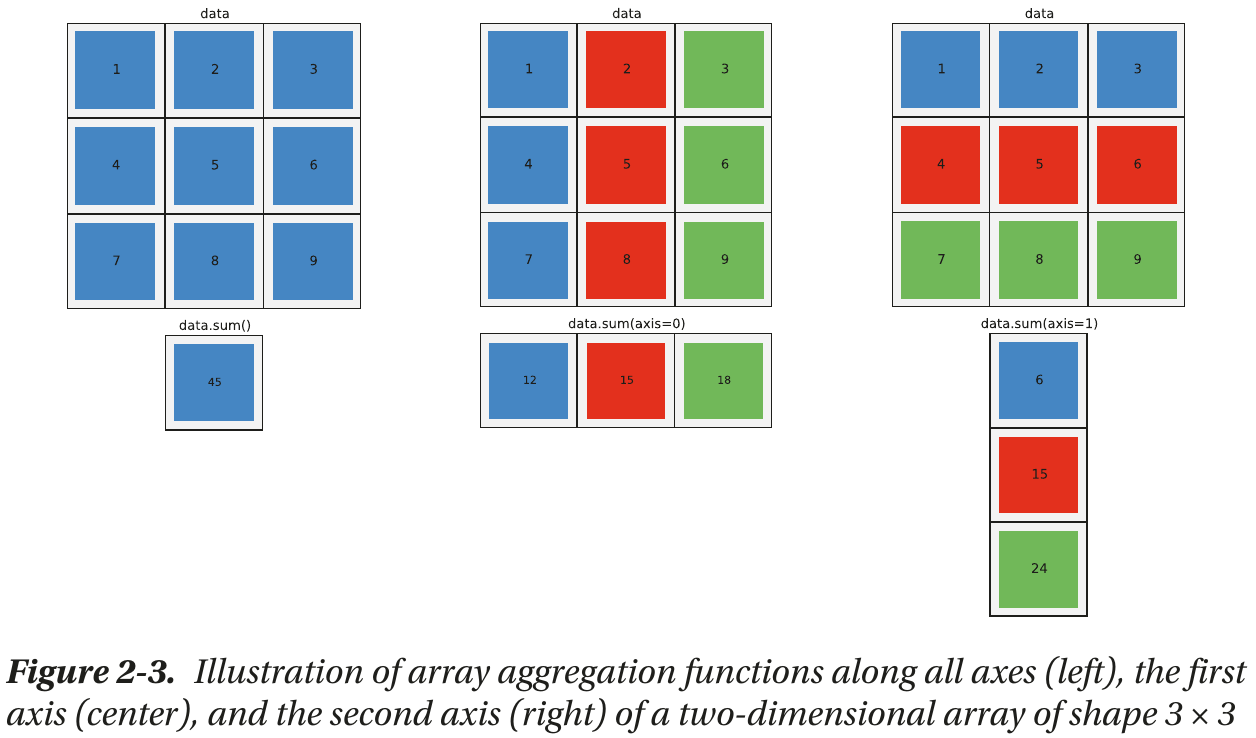

</div>

and we compute the aggregate sum of the entire array, over the axis 0, and over axis 1, respectively:

In [ ]:
r1 = np.sum(data4)
print(r1)
print(r1.shape)
print(thin_dash)

r2 = np.sum(data4, axis=0)
print(r2)
print(r2.shape)
print(thin_dash)

r3 = np.sum(data4, axis=1)
print(r3.shape)
print(r3)



45
()
─────────────────────────
[12 15 18]
(3,)
─────────────────────────
(3,)
[ 6 15 24]


### 📑 2.6.4 Boolean arrays and conditional expressions

When computing with NumPy arrays, there is often a need to compare elements in different arrays and perform conditional computations based on the results of such comparisons. Like with arithmetic operators, NumPy arrays can be used with the usual comparison  operators, for example, `>`, `<`, `>=`, `<=`, `==`, and `!=`, and the comparisons are made on an element-by-element basis. The broadcasting rules also apply to comparison operators, and if two operators have compatible shapes and sizes, the result of the comparison is a new array with Boolean values (with `dtype` as `np.bool`) that gives the result of the comparison for each element:

In [ ]:
g1 = np.array([1, 2, 3, 4])
g2 = np.array([4, 3, 2, 1])

g1 < g2

array([ True,  True, False, False])

To use the result of a comparison between arrays in, for example, an if statement, we need to aggregate the Boolean values of the resulting arrays in some suitable fashion, to obtain a single `True` or `False` value. A common use-case is to apply the `np.all` or `np.any` aggregation functions, depending on the situation at hand:

In [ ]:
k1 = np.all(g1 < g2)
print(k1)
k2 = np.any(g1 < g2)
print(k2)

print(thin_dash)

if np.all(g1 < g2):
    print("All elements in g1 are smaller than their corresponding element in g2.")

elif np.any(g1 < g2):
    print("Some elements in g1 are smaller than their corresponding element in g2.")

else:
    print("All elements in g2 are smaller than their corresponding element in g1.")

False
True
─────────────────────────
Some elements in g1 are smaller than their corresponding element in g2.


The advantage of Boolean-valued arrays, however, is that they often make it possible to avoid conditional `if` statements altogether. By using Boolean-valued arrays in arithmetic expressions, it is possible to write conditional computations in vectorized form. When appearing in an arithmetic expression together with a scalar number, or another NumPy array with a numerical data type, a Boolean array is converted to a numerical-­valued array with values `0` and `1` inplace of `False` and `True`, respectively.

In [ ]:
g3 = np.array([-2, -1, 0, 1, 2, 3])
print(g3 > 0)

output1_g3 = 1 * (g3 > 0)
print(output1_g3)

output2_g3 = g3 * (g3 > 0)
print(output2_g3)

[False False False  True  True  True]
[0 0 0 1 1 1]
[0 0 0 1 2 3]


In [ ]:
def pulse(x, position, height, width):
    return height * ((x >= position) & (x <= position + width))

x = np.linspace(-5, 5, 11)
# print(f"x = {x}, x.dtype = {x.dtype}, x.shape = {x.shape}, x.size = {x.size}, x.ndim = {x.ndim}, x.nbytes = {x.nbytes}")
pulse(x, position=-2, height=1, width=5)

array([0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0])

In this example, the expression `(x >= position) * (x <= (position + width))` is a
multiplication of two Boolean-valued arrays, and for this case the multiplication operator
acts as an elementwise AND operator. The function pulse could also be implemented
using NumPy’s function for elementwise AND operations, np.logical_and:

```python
def pulse(x, position, height, width):
    return height * np.logical_and(x >= position, x <= (position + width))
```

There are also functions for other logical operations, such as NOT, OR, and XOR, and functions for selectively picking values from different arrays depending on a given condition `np.where`, a list of conditions `np.select`, and an array of indices `np.choose`. See Table 2-10 for a summary of such functions, and the following examples demonstrate the basic usage of some of these functions. The `np.where` function selects elements from two arrays (second and third arguments), given a Boolean-valued array condition (the first argument). For elements where the condition is `True`, the corresponding values from the array given as second argument are selected, and if the condition is `False`, elements from the third argument array are selected:

<table align="center">
  <caption><strong>📑 Table 2-10.</strong> NumPy Functions for Conditional and Logical Expressions</caption>
  <thead>
    <tr>
      <th scope="col">Function</th>
      <th scope="col">Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><code>np.where</code></td>
      <td>Chooses values from two arrays depending on the value of a condition array.</td>
    </tr>
    <tr>
      <td><code>np.choose</code></td>
      <td>Chooses values from a list of arrays depending on the values of a given index array.</td>
    </tr>
    <tr>
      <td><code>np.select</code></td>
      <td>Chooses values from a list of arrays depending on a list of conditions.</td>
    </tr>
    <tr>
      <td><code>np.nonzero</code></td>
      <td>Returns an array with indices of nonzero elements.</td>
    </tr>
    <tr>
      <td><code>np.logical_and</code></td>
      <td>Performs an elementwise AND operation.</td>
    </tr>
    <tr>
      <td><code>np.logical_or</code>, <code>np.logical_xor</code></td>
      <td>Elementwise OR/XOR operations.</td>
    </tr>
    <tr>
      <td><code>np.logical_not</code></td>
      <td>Elementwise NOT operation (inverting).</td>
    </tr>
  </tbody>
</table>

In [ ]:
m = np.linspace(-4, 4, 9)
print(m)
print(f"m < 0: {1 * (m < 0)}")
print(f"m**2: {m**2}")
print(f"m**3: {m**3}")
print(thin_dash)
np.where(m < 0, m**2, m**3)


[-4. -3. -2. -1.  0.  1.  2.  3.  4.]
m < 0: [1 1 1 1 0 0 0 0 0]
m**2: [16.  9.  4.  1.  0.  1.  4.  9. 16.]
m**3: [-64. -27.  -8.  -1.   0.   1.   8.  27.  64.]
─────────────────────────


array([16.,  9.,  4.,  1.,  0.,  1.,  8., 27., 64.])

The `np.select` function works similarly, but instead of a Boolean-valued condition array, it expects a list of Boolean-valued condition arrays and a corresponding list of value arrays:

In [ ]:
print(m)
list_of_conditions = [m < -1, m < 2, m >= 2]
print(list_of_conditions[0])
print(list_of_conditions[1])
print(list_of_conditions[2])
print(type(m))
print(type(list_of_conditions))
print(len(list_of_conditions))
print(type(list_of_conditions[0]))
print(list_of_conditions[0].dtype)

print(thin_dash)

list_of_arrays = [m**2 , m**3 , m**4]
print(list_of_arrays[0])
print(list_of_arrays[1])
print(list_of_arrays[2])
print(type(list_of_arrays))
print(type(list_of_arrays[0]))
print(len(list_of_arrays))

print(thin_dash)

np.select(list_of_conditions, list_of_arrays)


[-4. -3. -2. -1.  0.  1.  2.  3.  4.]
[ True  True  True False False False False False False]
[ True  True  True  True  True  True False False False]
[False False False False False False  True  True  True]
<class 'numpy.ndarray'>
<class 'list'>
3
<class 'numpy.ndarray'>
bool
─────────────────────────
[16.  9.  4.  1.  0.  1.  4.  9. 16.]
[-64. -27.  -8.  -1.   0.   1.   8.  27.  64.]
[256.  81.  16.   1.   0.   1.  16.  81. 256.]
<class 'list'>
<class 'numpy.ndarray'>
3
─────────────────────────


array([ 16.,   9.,   4.,  -1.,   0.,   1.,  16.,  81., 256.])

📑 The `np.choose` function takes as a first argument a list or an array with indices that determine from which array in a given list of arrays an element is picked from:

In [ ]:
np.choose([0, 2, 0, 1, 0, 1, 0, 0, 0], list_of_arrays)

array([16., 81.,  4., -1.,  0.,  1.,  4.,  9., 16.])

The function `np.nonzero` returns a tuple of indices that can be used to index the array (e.g., the one that the condition was based on). This has the same results as indexing the array directly with `abs(x) > 2`, but it uses fancy indexing with the indices returned by `np.nonzero` rather than Boolean-valued array indexing.

In [ ]:
print(m)
print(abs(m) > 2)
print(np.nonzero(abs(m) > 2))
print(type(np.nonzero(abs(m) > 2)))

print(thin_dash)

print(m[np.nonzero(abs(m) > 2)])

print(thin_dash)

print(m[abs(m) > 2])

[-4. -3. -2. -1.  0.  1.  2.  3.  4.]
[ True  True False False False False False  True  True]
(array([0, 1, 7, 8]),)
<class 'tuple'>
─────────────────────────
[-4. -3.  3.  4.]
─────────────────────────
[-4. -3.  3.  4.]


### 2.6.5 Set operations

The Python language provides a convenient `set` data structure for managing unordered collections of unique objects. The NumPy array class ndarray can also be used to describe such sets, and NumPy contains functions for operating on sets stored as NumPy arrays. These functions are summarized in Table 2-11. Using NumPy arrays to describe and operate on sets allows expressing certain operations in vectorized form. For example, testing if the values in a NumPy array are included in a set can be done using the np.isin function, which tests for the existence of each element of its first argument in the array passed as the second argument. To see how this works, consider the following example: first, to ensure that a NumPy array is a proper set, we can use the np.unique function, which returns a new array with unique values:

<table align="center">
  <caption><strong>Table 2-11.</strong> NumPy Functions for Operating on Sets</caption>
  <thead>
    <tr>
      <th scope="col">Function</th>
      <th scope="col">Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><code>np.unique</code></td>
      <td>Creates a new array with unique elements, where each value only appears once.</td>
    </tr>
    <tr>
      <td><code>np.isin</code></td>
      <td>Tests for the existence of an array of elements in another array.</td>
    </tr>
    <tr>
      <td><code>np.intersect1d</code></td>
      <td>Returns an array with elements that are contained in two given arrays.</td>
    </tr>
    <tr>
      <td><code>np.setdiff1d</code></td>
      <td>Returns an array with elements that are contained in one, but not the other, of two given arrays.</td>
    </tr>
    <tr>
      <td><code>np.union1d</code></td>
      <td>Returns an array with elements that are contained in either, or both, of two given arrays.</td>
    </tr>
  </tbody>
</table>

In [ ]:
n1 = np.unique([1, 2, 3, 3])
n2 = np.unique([2, 3, 4, 4, 5, 6, 5])
print(n1)
print(n2)
np.isin(n1, n2)

[1 2 3]
[2 3 4 5 6]


array([False,  True,  True])

Here, the existence of each element in `n1` in the set `n2` was tested, and the result is a Boolean-valued array. Note that we can use the in keyword to test for the existence of individual elements in a set represented as NumPy array:

In [ ]:
print(1 in n1)
print(4 in n1)
print(2 in n2)
print(7 in n2)

True
False
True
False


To test if a is a subset of b, we can use the `np.isin` function, as in the previous example, together with the aggregation function `np.all` (or the corresponding ndarray method):

In [ ]:
print(np.all(np.isin(n1, n2)))

False


The standard set operations union (the set of elements included in either or both sets), intersection (elements included in both sets), and difference (elements included in one of the sets but not the other) are provided by `np.union1d`, `np.intersect1d`, and `np.setdiff1d`, respectively:

In [ ]:
print(np.union1d(n1, n2))
print(np.intersect1d(n1, n2))
print(np.setdiff1d(n1, n2))
print(np.setdiff1d(n2, n1))


[1 2 3 4 5 6]
[2 3]
[1]
[4 5 6]


### 2.6.6 Operations on arrays

In addition to elementwise and aggregation functions, some operations act on arrays as a whole and produce a transformed array of the same size. An example of this type of operation is the transpose, which flips the order of the axes of an array. For the special case of a two-dimensional array, i.e., a matrix, the transpose simply exchanges rows and columns:

In [ ]:
data3 = np.arange(9).reshape(3, 3)
print(data3)
print()
print(np.transpose(data3))
print()
print(data3.T)

[[0 1 2]
 [3 4 5]
 [6 7 8]]

[[0 3 6]
 [1 4 7]
 [2 5 8]]

[[0 3 6]
 [1 4 7]
 [2 5 8]]


The transpose function `np.transpose` also exists as a method in ndarray and as the special method name `ndarray.T`. For an arbitrary N-dimensional array, the transpose operation reverses all the axes, as can be seen from the following example (note that the shape attribute is used here to display the number of values along each axis of the array) :

In [ ]:
data4 = np.random.rand(1, 2, 3, 4, 5)
print(data4.shape)
print(np.transpose(data4).shape)

(1, 2, 3, 4, 5)
(5, 4, 3, 2, 1)


The `np.fliplr` (flip left-right) and `np.flipud` (flip up-down) functions perform operations that are similar to the transpose: they reshuffle the elements of an array so that the elements in rows (`np.fliplr`) or columns (`np.flipud`) are reversed, and the shape of the output array is the same as the input. The `np.rot90` function rotates the elements in the first two axes in an array by 90 degrees, and like the transpose function, it can change the shape of the array. Table 2-12 gives a summary of NumPy functions for common array operations.

<table align="center">
  <caption><strong>Table 2-12.</strong> Summary of NumPy Functions for Array Operations</caption>
  <thead>
    <tr>
      <th scope="col">Function</th>
      <th scope="col">Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><code>np.transpose</code>,<br><code>np.ndarray.transpose</code>,<br><code>np.ndarray.T</code></td>
      <td>The transpose (reverse axes) of an array.</td>
    </tr>
    <tr>
      <td><code>np.fliplr</code>/<code>np.flipud</code></td>
      <td>Reverse the elements in each row/column.</td>
    </tr>
    <tr>
      <td><code>np.rot90</code></td>
      <td>Rotates the elements along the first two axes by 90 degrees.</td>
    </tr>
    <tr>
      <td><code>np.sort</code>,<br><code>np.ndarray.sort</code></td>
      <td>Sort the elements of an array along a given specified axis (which defaults to the last axis of the array). The <code>np.ndarray.sort</code> method performs the sorting in place, modifying the input array.</td>
    </tr>
  </tbody>
</table>

---

## 2.7 Matrix and Vector Operations

We have so far discussed general N-dimensional arrays. One of the main applications of such arrays is to represent the mathematical concepts of vectors, matrices, and tensors, and in this use-case, we also frequently need to calculate vector and matrix operations such as scalar (inner) products, dot (matrix) products, and tensor (outer) products. A summary of NumPy’s functions for matrix operations is given in Table 2-13.

<table align="center">
  <caption><strong>Table 2-13.</strong> Summary of NumPy Functions for Matrix Operations</caption>
  <thead>
    <tr>
      <th scope="col">NumPy Function</th>
      <th scope="col">Description</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td><code>np.dot</code></td>
      <td>Matrix multiplication (dot product) between two given arrays representing vectors, arrays, or tensors.</td>
    </tr>
    <tr>
      <td><code>np.inner</code></td>
      <td>Scalar multiplication (inner product) between two arrays representing vectors.</td>
    </tr>
    <tr>
      <td><code>np.cross</code></td>
      <td>The cross product between two arrays that represent vectors.</td>
    </tr>
    <tr>
      <td><code>np.tensordot</code></td>
      <td>Dot product along specified axes of multidimensional arrays.</td>
    </tr>
    <tr>
      <td><code>np.outer</code></td>
      <td>Outer product (tensor product of vectors) between two arrays representing vectors.</td>
    </tr>
    <tr>
      <td><code>np.kron</code></td>
      <td>Kronecker product (tensor product of matrices) between arrays representing matrices and higher-dimensional arrays.</td>
    </tr>
    <tr>
      <td><code>np.einsum</code></td>
      <td>Evaluates Einstein’s summation convention for multidimensional arrays.</td>
    </tr>
  </tbody>
</table>

<p>
In NumPy, the * operator is used for elementwise multiplication. For two two-­
dimensional arrays A and B, the expression A * B therefore does not compute a matrix
product (in contrast to many other computing environments). Currently there is no
operator for denoting matrix multiplication,<sup><a href="#footnote-2" id="ref-2">2</a></sup> and instead the NumPy function np.dot
is used for this purpose. There is also a corresponding method in the ndarray class. To
compute the product of two matrices A and B, of size N × M and M × P, which results in a
matrix of size N × P, we can use:
</p>

<!-- footnote separator -->
<hr style="width: 100%; margin-left: 0;">

<!-- footnote -->
<p id="footnote-2" style="font-size: 0.9em;">
  <sup>2</sup> Python recently adopted the @ symbol for denoting matrix multiplication, and as of Python 3.5, this operator is now available.
</p>

In [ ]:
A1 = np.arange(1, 7).reshape(2, 3)
B1 = np.arange(1, 7).reshape(3, 2)
print(np.dot(A1, B1)) 
print(np.dot(B1, A1))

[[22 28]
 [49 64]]
[[ 9 12 15]
 [19 26 33]
 [29 40 51]]


The `np.dot` function can also be used for matrix-vector multiplication (i.e.,
multiplication of a two-dimensional array, which represents a matrix, with a one-
dimensional array representing a vector) . For example:,

In [ ]:
A2 = np.arange(9).reshape(3, 3)
print(A2)
print(A2.shape)

vector_1 = np.arange(3)
print()
print(vector_1)
print(vector_1.shape)

# matrix-vector multiplication
print()
print(np.dot(A2, vector_1))

[[0 1 2]
 [3 4 5]
 [6 7 8]]
(3, 3)

[0 1 2]
(3,)

[ 5 14 23]


In this example, `vector_1` can be either a two-dimensional array of shape (1, 3) or a one-
dimensional array with shape (3,). In addition to the function `np.dot`, there is also a
corresponding method `dot` in `ndarray`, which can be used as in the following example:

In [ ]:
print(A2.dot(vector_1))

[ 5 14 23]


Unfortunately, nontrivial matrix multiplication expressions can often become
complex and hard to read when using either np.dot or np.ndarray.dot. For example,
even a relatively simple matrix expression like the one for a similarity transform,
$A' = BAB^{-1}$, must be represented with relatively cryptic nested expressions<sup><a href="#footnote-3" id="ref-3">3</a></sup>, such as either

<!-- footnote separator -->
<hr style="width: 100%; margin-left: 0;">

<!-- footnote -->
<p id="footnote-3" style="font-size: 0.9em;">
  <sup>3</sup> With the new infix matrix multiplication operator, this same expression can be expressed as the
considerably more readable: <code>Ap = B @ A @ np.linalg.inv(B)</code>.
</p>

In [ ]:
A3 = np.random.rand(3, 3)
B3 = np.random.rand(3, 3)
Ap = np.dot(B3, np.dot(A3, np.linalg.inv(B3)))
print(Ap)

# alternative form
# Ap = B3.dot(A3.dot(np.linalg.inv(B3)))

[[-27.20899365  18.56849905  27.38649864]
 [-15.20708101  10.9064185   15.10218117]
 [-18.1805092   12.04072725  18.44224641]]


To improve this situation, NumPy provides an alternative data structure to
`ndarray` named `matrix`, for which expressions like $A * B$ are implemented as matrix
multiplication. It also provides some convenient special attributes, like `matrix.I` for the
inverse matrix and `matrix.H` for the complex conjugate transpose of a matrix. Using
instances of this matrix class, one can therefore use the vastly more readable expression:

In [ ]:
A4 = np.matrix(A3)
B4 = np.matrix(B3)
Ap = B4 * A4 * B4.I
print(Ap)

[[-27.20899365  18.56849905  27.38649864]
 [-15.20708101  10.9064185   15.10218117]
 [-18.1805092   12.04072725  18.44224641]]


This may seem like a practical compromise, but unfortunately using the `matrix` class
does have a few disadvantages, and its use is therefore often discouraged. The main
objection against using `matrix` is that expression like `A * B` is then context dependent:
that is, it is not immediately clear if `A * B` denotes elementwise or matrix multiplication,
because it depends on the type of A and B, and this creates another code-readability
problem. This can be a particularly relevant issue if A and B are user-supplied arguments
to a function, in which case it would be necessary to cast all input arrays explicitly to
matrix instances, using, for example, np.asmatrix or the function np.matrix (since
there would be no guarantee that the user calls the function with arguments of type
matrix rather than ndarray). The np.asmatrix function creates a view of the original
array in the form of an np.matrix instance. This does not add much in computational
costs, but explicitly casting arrays back and forth between ndarray and matrix does 
offset much of the benefits of the improved readability of matrix expressions. A related
issue is that some functions that operate on arrays and matrices might not respect the
type of the input and may return an ndarray even though it was called with an input
argument of type `matrix` might be unintentionally
converted to `ndarray`, which in turn would change the behavior of expressions like
`A * B`. This type of behavior is not likely to occur when using NumPy’s array and matrix
functions, but it is not unlikely to happen when using functions from other packages.
However, in spite of all the arguments for not using `matrix` matrices too extensively,
personally I think that using `matrix` class instances for complicated matrix expressions is
an important use-case, and in these cases, it might be a good idea to explicitly cast arrays
to `matrix` before the computation and explicitly cast the result back to the `ndarray`
type, following the pattern:

In [101]:
A4 = np.asmatrix(A3)
B4 = np.asmatrix(B3)
Ap = B4 * A4 * B4.I
Ap = np.asarray(Ap)


The inner product (scalar product) between two arrays representing vectors can be
computed using the `np.inner` function:

In [ ]:
np.inner(a, b)

np.float64(14.0)

or, equivalently, using `np.dot`:

In [ ]:
np.dot(a, b)

np.float64(14.0)

The main difference is that `np.inner` expects two input arguments with the same
dimension, while `np.dot` can take input vectors of shape 1 × N and N × 1, respectively:

In [ ]:
y8 = np.arange(3)
print(y8)
print(y8.shape)

print(thin_dash)

y8 = y8[:, np.newaxis] 
print(y8)
print(y8.shape)

print(thin_dash)

print(y8.T)
print(y8.T.shape)
print(np.dot(y8.T, y8))


[0 1 2]
(3,)
─────────────────────────
[[0]
 [1]
 [2]]
(3, 1)
─────────────────────────
[[0 1 2]]
(1, 3)
[[5]]


While the inner product maps two vectors to a scalar, the outer product performs the
complementary operation of mapping two vectors to a matrix.

In [ ]:
x9 = np.array([1, 3, 2])
np.outer(x9, x9)

array([[1, 3, 2],
       [3, 9, 6],
       [2, 6, 4]])

The outer product can also be calculated using the Kronecker product using the
function `np.kron`, which, however, in contrast to `np.outer`, produces an output array of
shape (M*P, N*Q) if the input arrays have shapes (M, N) and (P, Q), respectively. Thus,
for the case of two one-dimensional arrays of length M and P, the resulting array has
shape (M*P,) :

In [ ]:
np.kron(x9, x9)

array([1, 3, 2, 3, 9, 6, 2, 6, 4])

To obtain the result that corresponds to `np.outer(x, x)`, the input array x must be
expanded to shape (N, 1) and (1, N), in the first and second argument to np.kron,
respectively:

In [ ]:
np.kron(x9[:, np.newaxis], x9[np.newaxis, :])

array([[1, 3, 2],
       [3, 9, 6],
       [2, 6, 4]])

In general, while the `np.outer` function is primarily intended for vectors as input,
the `np.kron` function can be used for computing tensor products of arrays of arbitrary
dimension (but both inputs must have the same number of axes). For example, to
compute the tensor product of two 2 × 2 matrices, we can use:

In [ ]:
np.kron(np.ones((2,2)), np.identity(2))

array([[1., 0., 1., 0.],
       [0., 1., 0., 1.],
       [1., 0., 1., 0.],
       [0., 1., 0., 1.]])

In [ ]:
np.kron(np.identity(2), np.ones((2,2)))

array([[1., 1., 0., 0.],
       [1., 1., 0., 0.],
       [0., 0., 1., 1.],
       [0., 0., 1., 1.]])

---

## 2.8 Summary

In this chapter, we introduced array-based programming with NumPy, providing a foundation for the chapters that follow. NumPy is a core library for numerical computing in Python and underpins nearly all scientific and technical libraries in the Python ecosystem. Familiarity with NumPy and its common usage patterns is fundamental to scientific and technical computing with Python.

We began by introducing NumPy’s data structure for N-dimensional arrays, the `ndarray` class. We then discussed functions for creating and manipulating arrays, including indexing and slicing to access their elements. We also covered functions and operators for computations with `ndarray` objects, emphasizing vectorized expressions and
operations that enable efficient computation. Throughout the rest of this book, we will see examples of higher-level libraries for specific areas of scientific computing that build on NumPy’s array framework.

### Array-Based Programming

<div style="
    border-left: 5px solid #c7c7c7;
    background-color: #f7f7f7;
    padding: 12px 16px;
    margin: 12px 0;
    border-radius: 6px;
    font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', sans-serif;
    line-height: 1.5;
">

<p style="margin-top: 0;">


**What Is Array-Based Programming?**

- **Vectorized Operations:** Instead of using loops (for or while) to process items one by one, you apply a single instruction to an entire vector, matrix, or multidimensional array.
- **Implicit Data Parallelism:** Operations automatically generalize from individual numbers (scalars) to multi-dimensional data structures.
- **High-Level Abstraction:** It expresses complex mathematical and data-manipulation concepts concisely.

**Key Features**

- **Rank-Polymorphism:** Functions operate seamlessly across scalars, vectors, matrices, and higher-rank tensors.
- **Broadcasting & Reductions:** Languages can combine arrays of different shapes or reduce multidimensional data along specific axes (like summing columns or finding row maximums).
- **Memory & Locality:** Designed to leverage modern hardware, vector processors, GPUs, and cache-friendly memory layouts.

**Popular Array Programming Languages & Libraries**

- **Classic & Specialized Languages:** APL, J, and Fortran.
- **Scientific & Data Languages:** MATLAB, GNU Octave, R, Julia, and Perl Data Language (PDL).
- **Python Ecosystem:** Libraries like NumPy, CuPy, and Dask bring array programming and vectorization to Python.

</p>

</div>

---

## 2.9 Further Reading

The NumPy library is the topic of several books, including the *Guide to NumPy*, by the creator of the NumPy T. Oliphant, available for free online at http://web.mit.edu/dvp/Public/numpybook.pdf, and a series of books by Ivan Idris: *Numpy Beginner’s Guide (2015*), *NumPy Cookbook (2012)*, and *Learning NumPy Array (2014)*. NumPy is also covered in fair detail in McKinney (2013).

---

## 2.10 References

Idris, I. Learning NumPy Array. Mumbai: Packt, 2014. \
—. Numpy Beginner’s Guide. 3rd. Mumbai: Packt, 2015. \
—. NumPy Cookbook. Mumbai: Packt, 2012. \
McKinney, Wes. Python for Data Analysis. Sebastopol: O’Reilly, 2013.